## Evaluating Recommender System

### Step 1 - Importing Libraries.

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.metrics import mean_absolute_error, mean_squared_error 
from sklearn.metrics.pairwise import cosine_similarity 
TOP_K = 3 

### Step 2 - Load and Inspect the Data

In [4]:
movies = pd.read_csv("DSA4060_Week6_Movies.csv") 
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv") 
 
display(movies.head()) 
display(ratings.head()) 
 
print("Users:", ratings["user_id"].nunique()) 
print("Movies:", ratings["movie_id"].nunique()) 
print("Ratings:", len(ratings))

,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Users: 12
Movies: 20
Ratings: 120


1. What does one row in movies represent?

One row represents a single movie, identified by its unique movie_id, title, and genre information.

2. What does one row in ratings represent?

One row represents a user's rating of a particular movie. It contains the user_id, movie_id, numerical rating, and timestamp of the interaction.

3. How many unique users and movies are present?

- Unique users: 12
- Unique movies: 20
- Total ratings: 120
4. What type of feedback is the rating column?

The rating column contains explicit feedback because users directly provide numerical ratings for movies.

5. What is the rating scale?

The rating scale is from 1 to 5, where 1 represents a low rating and 5 represents a high rating.

### Step 3 – Inspect Rating Behaviour

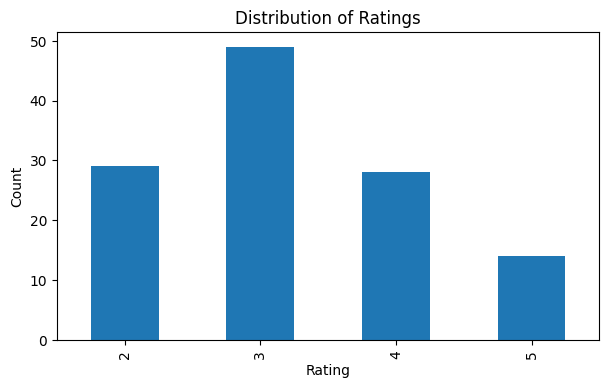

In [5]:
ratings["rating"].value_counts().sort_index() 
plt.figure(figsize=(7,4)) 
ratings["rating"].value_counts().sort_index().plot(kind="bar") 
plt.title("Distribution of Ratings") 
plt.xlabel("Rating") 
plt.ylabel("Count") 
plt.show()

Rating 3 is the most common, with approximately 49 ratings, followed by rating 2 (29), rating 4 (28), and rating 5 (14). This shows that moderate ratings dominate the dataset, while the highest ratings are least common. This imbalance may affect evaluation because models may predict moderate ratings more accurately than highly positive ratings.

### Step 4 – Create a Train/Test Split

In [6]:
ratings = ratings.sort_values(["user_id", "timestamp"]) 
 
test = ratings.groupby("user_id").tail(1).copy() 
train = ratings.drop(test.index).copy() 
 
print("Training interactions:", len(train)) 
print("Test interactions:", len(test)) 
display(test.head())

Training interactions: 108
Test interactions: 12


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


The most recent interaction for each user was held out for testing, while the remaining interactions were used for training. This approach evaluates the models on unseen interactions and reduces the risk of overly optimistic results caused by evaluating on data the models have already seen.

### Step 5 – Build a Popularity Baseline

In [7]:
global_mean = train["rating"].mean() 
 
movie_stats = ( 
    train.groupby("movie_id") 
    .agg( 
        mean_rating=("rating", "mean"), 
        rating_count=("rating", "size") 
    ) 
    .reset_index() 
    .merge(movies[["movie_id", "title"]], on="movie_id") 
) 
 
movie_stats.sort_values( 
    ["mean_rating", "rating_count"], 
    ascending=[False, False] 
).head(10) 
movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict() 
 
baseline_test = test.copy() 
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map) 
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean) 

### Step 6 – Evaluate the Baseline with MAE and RMSE 

In [8]:
def rating_metrics(actual, predicted): 
    mae = mean_absolute_error(actual, predicted) 
    rmse = np.sqrt(mean_squared_error(actual, predicted)) 
    return mae, rmse 
 
baseline_mae, baseline_rmse = rating_metrics( 
    baseline_test["rating"], 
    baseline_test["prediction"] 
) 
 
print("Baseline MAE:", round(baseline_mae, 3)) 
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 1.086
Baseline RMSE: 1.201


The baseline MAE is 1.086, meaning predictions differ from actual ratings by an average of 1.086 points. The RMSE is 1.201, indicating that larger prediction errors have a greater impact on the overall error.

### Step 7 – Build Item Features for Content-Based Filtering

In [9]:
genre_features = movies["genres"].str.get_dummies(sep="|") 
 
content_items = pd.concat( 
    [movies[["movie_id", "title"]], genre_features], 
    axis=1 
) 
 
genre_columns = genre_features.columns.tolist() 
item_feature_matrix = content_items.set_index("movie_id")[genre_columns] 
 
display(content_items.head())

,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


### Step 8 – Build a User Preference Profile

In [10]:
def build_user_profile(user_id, train_data): 
    history = train_data[train_data["user_id"] == user_id] 
 
    ids = history["movie_id"].values 
    ratings_array = history["rating"].values.reshape(-1, 1) 
    features = item_feature_matrix.loc[ids].values 
 
    return (features * ratings_array).mean(axis=0) 
 
profile = build_user_profile(1, train) 
 
pd.Series( 
    profile, 
    index=genre_columns 
).sort_values(ascending=False) 

Drama        1.666667
Sci-Fi       1.000000
Comedy       0.888889
Romance      0.666667
Action       0.555556
Family       0.555556
Crime        0.333333
Mystery      0.333333
Adventure    0.222222
dtype: float64

These results suggest that Drama and Sci-Fi are the strongest genres in User 1's learned preference profile. However, the saved output does not include the complete list of User 1's highly rated training movies, so I cannot independently verify the agreement with those movies

### Step 9 – Content-Based Rating Prediction

In [11]:
def content_score(user_id, movie_id, train_data): 
    profile = build_user_profile(user_id, train_data).reshape(1, -1) 
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1) 
 
    sim = cosine_similarity(profile, item_vec)[0, 0] 
 
    return float(np.clip(1 + 4 * sim, 1, 5)) 
 
content_test = test.copy() 
content_test["prediction"] = content_test.apply( 
    lambda r: content_score(r["user_id"], r["movie_id"], train), 
    axis=1 
)
content_mae, content_rmse = rating_metrics( 
    content_test["rating"], 
    content_test["prediction"] 
) 
 
print("Content MAE:", round(content_mae, 3)) 
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


The Content-Based model has an MAE of 1.094 and an RMSE of 1.381. It performs slightly worse than the popularity baseline on both metrics, indicating less accurate rating predictions.

### Step 10 – Build Item-Based Collaborative Filtering 

In [12]:
user_item = train.pivot_table( 
    index="user_id", 
    columns="movie_id", 
    values="rating" 
) 
 
item_user = user_item.T.fillna(0) 
 
item_similarity = pd.DataFrame( 
    cosine_similarity(item_user), 
    index=item_user.index, 
    columns=item_user.index 
) 
 
item_similarity.iloc[:5, :5] 

movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


### Step 11 – Item-Based Rating Prediction

In [13]:
def item_cf_predict(user_id, movie_id, train_data): 
    history = train_data[train_data["user_id"] == user_id] 
 
    weighted_sum = 0.0 
    similarity_sum = 0.0 
 
    for row in history.itertuples(): 
        if movie_id in item_similarity.index and row.movie_id in item_similarity.columns: 
            sim = item_similarity.loc[movie_id, row.movie_id] 
 
            if sim > 0: 
                weighted_sum += sim * row.rating 
                similarity_sum += sim 
 
    if similarity_sum == 0: 
        return global_mean 
 
    return weighted_sum / similarity_sum 
 
cf_test = test.copy() 
cf_test["prediction"] = cf_test.apply( 
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train), 
    axis=1 
) 
 
cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"], 
    cf_test["prediction"] 
)

print("Collaborative MAE:", round(cf_mae, 3)) 
print("Collaborative RMSE:", round(cf_rmse, 3))

Collaborative MAE: 0.924
Collaborative RMSE: 1.07


### Step 12 – Compare Rating Prediction Metrics

In [14]:
rating_results = pd.DataFrame({ 
    "Model": [ 
        "Popularity Baseline", 
        "Content-Based", 
        "Item-Based CF" 
    ], 
    "MAE": [baseline_mae, content_mae, cf_mae], 
    "RMSE": [baseline_rmse, content_rmse, cf_rmse] 
}) 
 
rating_results.sort_values("MAE") 

,Model,MAE,RMSE
2,Item-Based CF,0.924315,1.069675
0,Popularity Baseline,1.085913,1.201011
1,Content-Based,1.093920,1.380701


6. Which model has the lowest MAE?

Item-Based Collaborative Filtering, with an MAE of 0.924.

7. Which model has the lowest RMSE?

Item-Based Collaborative Filtering, with an RMSE of 1.070.

8. Does either advanced model clearly beat the baseline?

Yes. Item-Based Collaborative Filtering outperforms the baseline on both MAE and RMSE, while Content-Based Filtering performs slightly worse.

9. Why should you avoid declaring a model best from only one metric?

Different metrics measure different aspects of performance. A model may predict ratings accurately but perform poorly in ranking relevant recommendations, coverage, novelty, or diversity.

### Step 13 – Move from Rating Prediction to Ranking Evaluation 

In [15]:
test["relevant"] = test["rating"] >= 4 
 
test[["user_id", "movie_id", "rating", "relevant"]].head()

,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False


The test data contains one held-out interaction per user. A held-out movie rated 4 or 5 is therefore treated as relevant for evaluating the Top-3 recommendations. This allows the evaluation to focus on whether the models recommend relevant movies rather than merely predicting ratings accurately.

### Step 14 – Build Top-N Recommendation Functions

In [16]:
all_movie_ids = movies["movie_id"].tolist() 
 
def unseen_movies(user_id): 
    seen = set( 
        train.loc[train["user_id"] == user_id, "movie_id"] 
    ) 
    return [m for m in all_movie_ids if m not in seen] 
 
popularity_order = ( 
    movie_stats 
    .sort_values(["mean_rating", "rating_count"], ascending=[False, False]) 
    ["movie_id"].tolist() 
) 
 
def recommend_popularity(user_id, k=3): 
    unseen = set(unseen_movies(user_id)) 
    return [m for m in popularity_order if m in unseen][:k] 
 
def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)] 
    scored.sort(key=lambda x: x[1], reverse=True) 
    return [m for m, s in scored[:k]] 
 
def recommend_cf(user_id, k=3): 
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)] 
    scored.sort(key=lambda x: x[1], reverse=True) 
    return [m for m, s in scored[:k]] 
print("Popularity:", recommend_popularity(1)) 
print("Content:", recommend_content(1)) 
print("Collaborative:", recommend_cf(1))

Popularity: [6, 18, 16]
Content: [16, 6, 18]
Collaborative: [12, 11, 18]


The Collaborative Filtering model appears most personalized because it recommends a different combination of movies. The Popularity Baseline is easiest to explain because it recommends movies based on their average ratings and rating counts.

### Step 15 – Precision@K, Recall@K, and NDCG@K 

In [18]:
# --------------------------------------------------
# 1. Precision@K and Recall@K
# --------------------------------------------------

def precision_recall_at_k(recs, relevant, k):
    recs = recs[:k]

    hits = len(set(recs) & set(relevant))

    # Precision: proportion of recommendations that are relevant
    precision = hits / k if k > 0 else np.nan

    # Recall: proportion of relevant movies that were recommended
    recall = hits / len(relevant) if relevant else np.nan

    return precision, recall


# --------------------------------------------------
# 2. NDCG@K
# --------------------------------------------------

def ndcg_at_k(recs, relevant, k):
    dcg = 0.0

    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)

    ideal_hits = min(len(relevant), k)

    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )

    return dcg / idcg if idcg > 0 else np.nan


# --------------------------------------------------
# 3. Evaluate a recommender using ranking metrics
# --------------------------------------------------

def evaluate_ranking(recommender, k=3):
    rows = []

    for user_id in sorted(test["user_id"].unique()):

        # Movies in the test set rated 4 or higher
        relevant = test.loc[
            (test["user_id"] == user_id) &
            (test["rating"] >= 4),
            "movie_id"
        ].tolist()

        # Skip users with no relevant movies in the test set
        if not relevant:
            continue

        # Generate recommendations for this user
        recs = recommender(user_id, k)

        precision, recall = precision_recall_at_k(
            recs, relevant, k
        )

        ndcg = ndcg_at_k(recs, relevant, k)

        rows.append({
            "user_id": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg
        })

    result = pd.DataFrame(rows)

    # Handle the case where no users have relevant test movies
    if result.empty:
        return {
            f"Precision@{k}": np.nan,
            f"Recall@{k}": np.nan,
            f"NDCG@{k}": np.nan
        }

    # Calculate average ranking metrics across evaluated users
    return {
        f"Precision@{k}": result["Precision@K"].mean(),
        f"Recall@{k}": result["Recall@K"].mean(),
        f"NDCG@{k}": result["NDCG@K"].mean()
    }


# --------------------------------------------------
# 4. Set the number of recommendations
# --------------------------------------------------

TOP_K = 3


# --------------------------------------------------
# 5. Evaluate all three recommender systems
# --------------------------------------------------

pop_rank = evaluate_ranking(
    recommend_popularity,
    TOP_K
)

content_rank = evaluate_ranking(
    recommend_content,
    TOP_K
)

cf_rank = evaluate_ranking(
    recommend_cf,
    TOP_K
)


# --------------------------------------------------
# 6. Create the ranking results comparison table
# --------------------------------------------------

ranking_results = pd.DataFrame([
    {
        "Model": "Popularity Baseline",
        **pop_rank
    },
    {
        "Model": "Content-Based",
        **content_rank
    },
    {
        "Model": "Item-Based CF",
        **cf_rank
    }
])


# --------------------------------------------------
# 7. Display results
# --------------------------------------------------

print(f"Ranking Evaluation Results (K={TOP_K})")
display(ranking_results.round(4))


Ranking Evaluation Results (K=3)


,Model,Precision@3,Recall@3,NDCG@3
0,Popularity Baseline,0.0667,0.2,0.1
1,Content-Based,0.0667,0.2,0.2
2,Item-Based CF,0.0000,0.0,0.0


### Step 16 – Catalogue Coverage

In [19]:
def catalogue_coverage(recommender, k=3): 
    recommended = set() 
 
    for user_id in train["user_id"].unique(): 
        recommended.update(recommender(user_id, k)) 
 
    return len(recommended) / movies["movie_id"].nunique() 
 
coverage_results = pd.DataFrame({ 
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"], 
    "Coverage": [ 
        catalogue_coverage(recommend_popularity), 
        catalogue_coverage(recommend_content), 
        catalogue_coverage(recommend_cf) 
    ] 
}) 
 
coverage_results

,Model,Coverage
0,Popularity Baseline,0.35
1,Content-Based,0.70
2,Item-Based CF,0.85


### Step 17 – Novelty

In [20]:
pop_counts = train["movie_id"].value_counts().to_dict() 
num_users = train["user_id"].nunique() 
 
def novelty_of_item(movie_id): 
    p = pop_counts.get(movie_id, 1) / num_users 
    return -np.log2(p) 
def average_novelty(recommender, k=3): 
    values = [] 
 
    for user_id in train["user_id"].unique(): 
        recs = recommender(user_id, k) 
        values.extend([novelty_of_item(m) for m in recs]) 
 
    return np.mean(values) 
novelty_results = pd.DataFrame({ 
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"], 
    "Novelty": [ 
        average_novelty(recommend_popularity), 
        average_novelty(recommend_content), 
        average_novelty(recommend_cf) 
    ] 
}) 
 
novelty_results 

,Model,Novelty
0,Popularity Baseline,1.689432
1,Content-Based,1.343556
2,Item-Based CF,1.694791


### Step 18 – Diversity

In [21]:
genre_similarity = pd.DataFrame( 
    cosine_similarity(item_feature_matrix), 
    index=item_feature_matrix.index, 
    columns=item_feature_matrix.index 
) 
 
def list_diversity(movie_ids): 
    sims = [] 
 
    for i in range(len(movie_ids)): 
        for j in range(i + 1, len(movie_ids)): 
            sims.append( 
                genre_similarity.loc[movie_ids[i], movie_ids[j]] 
            ) 
 
    return 1 - np.mean(sims) if sims else 0 
 
def average_diversity(recommender, k=3): 
    return np.mean([ 
        list_diversity(recommender(user_id, k)) 
        for user_id in train["user_id"].unique() 
    ]) 
diversity_results = pd.DataFrame({ 
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"], 
    "Diversity": [ 
        average_diversity(recommend_popularity), 
        average_diversity(recommend_content), 
        average_diversity(recommend_cf) 
    ] 
}) 
 
diversity_results

,Model,Diversity
0,Popularity Baseline,0.736111
1,Content-Based,0.541667
2,Item-Based CF,0.780161


### Step 19 – Build a Unified Evaluation Table

In [22]:
summary = ( 
rating_results 
.merge(ranking_results, on="Model") 
.merge(coverage_results, on="Model") 
.merge(novelty_results, on="Model") 
.merge(diversity_results, on="Model") 
) 
summary

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.085913,1.201011,0.066667,0.2,0.1,0.35,1.689432,0.736111
1,Content-Based,1.093920,1.380701,0.066667,0.2,0.2,0.70,1.343556,0.541667
2,Item-Based CF,0.924315,1.069675,0.000000,0.0,0.0,0.85,1.694791,0.780161


### Step 20 – Interpret Evaluation Trade-Offs

A recommender may predict ratings accurately but rank relevant movies poorly. Models also differ in coverage, novelty, diversity, and explainability, so the best choice depends on the business objective.

### Step 21 – Final Business Scenario 

10. Which model would you choose?

I would choose Item-Based Collaborative Filtering because it achieves the highest coverage, novelty, and diversity, helping users discover a wider range of movies.

11. Which 2–3 metrics influenced your choice most?

Catalogue coverage (0.85), diversity (0.780), and novelty (1.695).

12. What trade-off are you accepting?

I accept that greater movie variety may come at the expense of relevance because Collaborative Filtering recorded zero on all three ranking metrics.

13. State one limitation of this evaluation.

The dataset is small, containing only 12 users and 20 movies, so the results may not generalize to a larger streaming service.

### Step 22 – Extension Challenge

Option C – Compare personalization: show recommendations for two users from all three models and explain which 
models genuinely personalize.